# Analyse Exploratoire des Données

## 1. Chargement Initial & Inspection des Données

In [1]:
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Configuration esthétique des graphiques
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12


In [2]:
PROJECT_ROOT = Path("..")
SAMPLE_PATH = PROJECT_ROOT / "data" / "processed" / "hespress" / "comments_sample.csv"
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "hespress" / "v1"

# Chargement du corpus échantillonné
df_sample = pd.read_csv(SAMPLE_PATH, encoding='utf-8-sig')

# Enrichissement avec les scores de votes réels issus des fichiers bruts originaux
raw_scores = {}
topic_files = {
    'politique': 'comments_politique.csv',
    'economie': 'comments_economie.csv',
    'societe': 'comments_societe.csv',
    'sport': 'comments_sport.csv',
    'art-et-culture': 'comments_art-et-culture.csv'
}

for topic, filename in topic_files.items():
    filepath = RAW_DIR / filename
    if filepath.exists():
        raw_df = pd.read_csv(filepath, usecols=['Unnamed: 0', 'score'])
        for _, row in raw_df.iterrows():
            raw_scores[(filename, int(row['Unnamed: 0']))] = row['score']

df_sample['score'] = df_sample.apply(
    lambda r: raw_scores.get((r['source_file'], int(r['source_record'])), 0), axis=1
)
df_sample['score'] = pd.to_numeric(df_sample['score'], errors='coerce').fillna(0).astype(int)

df = df_sample.copy()
print(f"Données chargées : {df.shape[0]} lignes, {df.shape[1]} colonnes.")

Données chargées : 1000 lignes, 16 colonnes.


In [3]:
# Aperçu des 5 premières lignes
df.head()

,sample_id,source,source_file,source_record,article_id,comment_text,article_topic,article_title,article_date_raw,event_time,language,sentiment,theme_label,sentiment_annotator,theme_annotator,score
0,hespress:v1:politique:38357,hespress,comments_politique.csv,38357,48a5591004e011eb85bb646e69d991ea,البوليزاريو على أرض الجزائر وهي متورطة كمن يرب...,politique,"بوريطة: بيانات ""خارجية الجزائر"" دليل تورط الجا...",الخميس 23 يناير 2020 - 21:00,NaN,inconnu,NaN,NaN,NaN,NaN,-68
1,hespress:v1:politique:33459,hespress,comments_politique.csv,33459,b249bcd804df11eb859f646e69d991ea,ما على اتباع النظام الجزائري الغادر الا فتح قن...,politique,"المملكة تعزز مغربية الصحراء بفتح ""قنصلية كوت د...",الثلاثاء 18 فبراير 2020 - 19:45,NaN,inconnu,NaN,NaN,NaN,NaN,19
2,hespress:v1:politique:19361,hespress,comments_politique.csv,19361,b9aaa89204de11eb8887646e69d991ea,و هل يوجد حجر صحي أصلا الفوضى تعم أسواق و شوار...,politique,"العثماني يعلن تمديد ""الحجر الصحي"" إلى غاية 10 ...",الاثنين 18 ماي 2020 - 14:15,NaN,inconnu,NaN,NaN,NaN,NaN,10
3,hespress:v1:politique:36262,hespress,comments_politique.csv,36262,0cb3766e04e011ebb24d646e69d991ea,اعتذر من السادة القراء واقول للسيد العثماني هذ...,politique,"العثماني: إبقاء الساعة الإضافية من ""زيادات الخ...",الأحد 02 فبراير 2020 - 17:00,NaN,inconnu,NaN,NaN,NaN,NaN,16
4,hespress:v1:politique:13666,hespress,comments_politique.csv,13666,5fc8444804de11eb9c69646e69d991ea,دينامية كبيرة وغير مسبوقة في الحقل السياسي هي ...,politique,"""التجمع"" يسائل العثماني عن ""عريضة الحياة""",الاثنين 29 يونيو 2020 - 23:16,NaN,inconnu,NaN,NaN,NaN,NaN,-8


In [4]:
# Aperçu des 5 dernières lignes
df.tail()

,sample_id,source,source_file,source_record,article_id,comment_text,article_topic,article_title,article_date_raw,event_time,language,sentiment,theme_label,sentiment_annotator,theme_annotator,score
995,hespress:v1:art-et-culture:6962,hespress,comments_art-et-culture.csv,6962,15c8ce18055111eb8984646e69d991ea,الى الاخت لمياء ارجوك لا تجمعين المنتقيد كلهم ...,art-et-culture,"هدى سعد تنخرط في ""كورونيات"" بأغنية ""الرجا فالله""",السبت 28 مارس 2020 - 10:30,NaN,inconnu,NaN,NaN,NaN,NaN,42
996,hespress:v1:art-et-culture:2713,hespress,comments_art-et-culture.csv,2713,bf1b0cc0054f11eb8c04646e69d991ea,شفاه الله و عافاه ، مسيحي كرس فنه و حياته للدف...,art-et-culture,"بعد جراحة ناجحة .. مغاربة لخليفة: ""سلامة قلبك""",الثلاثاء 28 يوليوز 2020 - 21:41,NaN,inconnu,NaN,NaN,NaN,NaN,25
997,hespress:v1:art-et-culture:5588,hespress,comments_art-et-culture.csv,5588,b5d462a4055011ebab4a646e69d991ea,إن سولحيفة تأتر عقول الأطفال ولهذا تريد وزارة ...,art-et-culture,"موجة انتقادات تلاحق السلسلة التلفزية ""سوحليفة""",الأحد 03 ماي 2020 - 18:40,NaN,inconnu,NaN,NaN,NaN,NaN,-1
998,hespress:v1:art-et-culture:5832,hespress,comments_art-et-culture.csv,5832,c36588c8055011ebb37d646e69d991ea,اذا كثر الأعداء أعلم أنك ناجح\nأمور مثل هاته أ...,art-et-culture,قناة تونسية تثير الغضب للسخرية من رموز المملكة,الخميس 30 أبريل 2020 - 17:05,NaN,inconnu,NaN,NaN,NaN,NaN,100
999,hespress:v1:art-et-culture:5216,hespress,comments_art-et-culture.csv,5216,a6b802c6055011eb8da6646e69d991ea,ا لى العربي بن مهيدي number3 . المغاربة سرقوا ...,art-et-culture,"إيدير .. مسار ""فنان أسطورة"" رفض النجومية وواجه...",الجمعة 08 ماي 2020 - 05:00,NaN,inconnu,NaN,NaN,NaN,NaN,9


In [5]:
# Dimensions du DataFrame
print("Dimensions du DataFrame :", df.shape)

Dimensions du DataFrame : (1000, 16)


In [6]:
# Informations structurelles et types de colonnes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   sample_id            1000 non-null   object 
 1   source               1000 non-null   object 
 2   source_file          1000 non-null   object 
 3   source_record        1000 non-null   int64  
 4   article_id           1000 non-null   object 
 5   comment_text         1000 non-null   object 
 6   article_topic        1000 non-null   object 
 7   article_title        1000 non-null   object 
 8   article_date_raw     1000 non-null   object 
 9   event_time           0 non-null      float64
 10  language             1000 non-null   object 
 11  sentiment            0 non-null      float64
 12  theme_label          0 non-null      float64
 13  sentiment_annotator  0 non-null      float64
 14  theme_annotator      0 non-null      float64
 15  score                1000 non-null   in

In [7]:
# Statistiques descriptives des variables numériques
df.describe()

,source_record,event_time,sentiment,theme_label,sentiment_annotator,theme_annotator,score
count,1000.000000,0.0,0.0,0.0,0.0,0.0,1000.00000
mean,13406.395000,NaN,NaN,NaN,NaN,NaN,19.14500
std,12100.324106,NaN,NaN,NaN,NaN,NaN,69.68637
min,6.000000,NaN,NaN,NaN,NaN,NaN,-819.00000
25%,4025.250000,NaN,NaN,NaN,NaN,NaN,1.00000
50%,8455.000000,NaN,NaN,NaN,NaN,NaN,6.00000
75%,20749.000000,NaN,NaN,NaN,NaN,NaN,21.25000
max,46536.000000,NaN,NaN,NaN,NaN,NaN,781.00000


In [8]:
# Statistiques descriptives des variables catégorielles et textuelles
df.describe(include=['O', 'object'])

,sample_id,source,source_file,article_id,comment_text,article_topic,article_title,article_date_raw,language
count,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,1000,1,5,805,1000,5,804,805,1
top,hespress:v1:art-et-culture:5216,hespress,comments_politique.csv,e32199c0055e11eb9e9e646e69d991ea,ا لى العربي بن مهيدي number3 . المغاربة سرقوا ...,politique,الحداوي: راتبي أربعة ملايين .. والحسن الثاني و...,السبت 30 ماي 2020 - 13:00,inconnu
freq,1,1000,200,6,1,200,6,6,1000


## 2. Nettoyage des données

Dans cette section essentielle, nous répondons à deux impératifs :
1. **Audit colonne par colonne** pour identifier toute trace de donnée sale ( textes corrompus, balises HTML, répétitions abusives, espaces invisibles, incohérences de dates ou de scores).
2. **Résolution de la colonne `language`** : à l'origine, 100% des lignes avaient la valeur `"inconnu"` car le corpus brut n'avait pas encore été annoté. Nous implémentons un classifieur linguistique pour détecter et affecter la langue réelle (`arabe`, `darija`, `français`, `mixte`).

In [9]:
# Audit Systématique Colonne par Colonne
audit_results = []

for col in df.columns:
    n_null = df[col].isnull().sum()
    pct_null = (n_null / len(df)) * 100
    n_unique = df[col].nunique()
    dtype = str(df[col].dtype)
    sample_val = str(df[col].dropna().iloc[0])[:30] if n_null < len(df) else "TOTALEMENT NULL"

    # Détection d'anomalies
    dirty_flag = "NON"
    if n_null == len(df):
        dirty_flag = "OUI (100% manquant)"
    elif col == 'language' and (df[col] == 'inconnu').all():
        dirty_flag = "OUI (100% inconnu)"
    elif col == 'comment_text':
        dirty_flag = "OUI (caractères répétés, HTML)"

    audit_results.append({
        'Colonne': col,
        'Type': dtype,
        'Valeurs Nulles': n_null,
        '% Nul': f"{pct_null:.1f}%",
        'Valeurs Uniques': n_unique,
        'Donnée Sale Détectée': dirty_flag,
        'Exemple': sample_val
    })

pd.DataFrame(audit_results)

,Colonne,Type,Valeurs Nulles,% Nul,Valeurs Uniques,Donnée Sale Détectée,Exemple
0,sample_id,object,0,0.0%,1000,NON,hespress:v1:politique:38357
1,source,object,0,0.0%,1,NON,hespress
2,source_file,object,0,0.0%,5,NON,comments_politique.csv
3,source_record,int64,0,0.0%,988,NON,38357
4,article_id,object,0,0.0%,805,NON,48a5591004e011eb85bb646e69d991
5,comment_text,object,0,0.0%,1000,"OUI (caractères répétés, HTML)",البوليزاريو على أرض الجزائر وه
6,article_topic,object,0,0.0%,5,NON,politique
7,article_title,object,0,0.0%,804,NON,"بوريطة: بيانات ""خارجية الجزائر"
8,article_date_raw,object,0,0.0%,805,NON,الخميس 23 يناير 2020 - 21:00
9,event_time,float64,1000,100.0%,0,OUI (100% manquant),TOTALEMENT NULL


In [10]:
# Détection précise des anomalies textuelles
# Balises pseudo-HTML ou chevrons
html_mask = df['comment_text'].str.contains(r'<[^>]+>|<<|>>', regex=True)
print(f"Commentaires avec balises / chevrons (HTML-like) : {html_mask.sum()}")

# Répétitions excessives de caractères (allongement expressif ex: هههههههههههه, .........)
rep_mask = df['comment_text'].str.contains(r'(.)\1{4,}', regex=True)
print(f"Commentaires avec répétitions excessives (>= 5 fois) : {rep_mask.sum()}")

# C. Caractères invisibles / espaces insécables zéro-largeur
zero_width_mask = df['comment_text'].apply(
    lambda t: any(c in ['\u200b', '\u200c', '\u200d', '\ufeff', '\xa0'] for c in str(t))
)
print(f"Commentaires avec espaces insécables zéro-largeur : {zero_width_mask.sum()}")

# D. Commentaires trop courts (< 15 caractères)
short_mask = df['comment_text'].str.len() < 15
print(f"Commentaires trop courts (< 15 caractères) : {short_mask.sum()}")

Commentaires avec balises / chevrons (HTML-like) : 1
Commentaires avec répétitions excessives (>= 5 fois) : 57
Commentaires avec espaces insécables zéro-largeur : 1
Commentaires trop courts (< 15 caractères) : 0


In [11]:
# 2.3 Nettoyage approfondi des données sales (Cleaning pipeline)
def clean_comment_text(text):
    text = str(text)
    # 1. Remplacement des espaces insécables et zéro-largeur
    for char in ['\u200b', '\u200c', '\u200d', '\ufeff', '\xa0']:
        text = text.replace(char, ' ')
    # 2. Suppression des balises HTML et chevrons
    text = re.sub(r'<[^>]+>', ' ', text)
    text = text.replace('<<', ' ').replace('>>', ' ')
    # 3. Réduction des répétitions abusives de caractères (max 2 répétitions consécutives, correction du bug \1)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    # 4. Normalisation des espaces et sauts de ligne
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['comment_text_clean'] = df['comment_text'].apply(clean_comment_text)

# Vérification des doublons après nettoyage
n_dup = df['comment_text_clean'].duplicated().sum()
print(f"Doublons détectés après normalisation : {n_dup}")
df = df.drop_duplicates(subset=['comment_text_clean']).reset_index(drop=True)
print(f"Dataset après déduplication : {df.shape[0]} lignes valides.")

Doublons détectés après normalisation : 0
Dataset après déduplication : 1000 lignes valides.


### 2.4 Résolution Complète de la Colonne `language`

À l'origine, la colonne `language` contenait 100% de `"inconnu"` dans le fichier brut.  
Nous mettons en place un **algorithme d'identification linguistique** fondé sur :
1. **L'alphabet utilisé** : Arabe vs Latin vs Mixte.
2. **Les marqueurs lexicaux de la Darija marocaine en graphie arabe** (ex: *ديال, دابا, باش, غادي, زوين, مزيان, بزاف, كاين, واش, هاد, علاش, فاش, درتو, كاي, كولشي, فلوس, حيت, الخ*).
3. **Les marqueurs du Français en alphabet latin** (*mots outils français : le, la, les, de, pour, avec, dans, etc.*).
4. **L'Arabizi** (Darija écrite en caractères latins et chiffres : *zwin, mzyan, bzaf, 3afak, khouya, etc.*).

In [12]:
# Algorithme de détection de la langue réelle (Résolution de "inconnu")

DARIJA_AR_MARKERS = {
    'ديال', 'دابا', 'باش', 'غادي', 'زوين', 'زوينة', 'مزيان', 'مزيانة', 'بزاف',
    'كاين', 'كاينا', 'كاينين', 'ماعند', 'واش', 'راه', 'راها', 'راهم', 'هاد',
    'هادو', 'هاديك', 'هادا', 'حنا', 'علاش', 'فاش', 'درتو', 'درna', 'كنديرو',
    'داك', 'ديك', 'مابقاتش', 'خاصنا', 'مكاينش', 'مابغاش', 'دبا', 'غدا', 'بغا',
    'شكون', 'فلوس', 'حيت', 'ولكن', 'دير', 'دارو', 'كولشي', 'عنداك', 'دبا',
    'غير', 'واحد', 'شي', 'زوينين', 'ولاد', 'بنات', 'بيناتهم', 'بلا', 'طالع'
}

FRENCH_STOPWORDS = {
    'le', 'la', 'les', 'de', 'des', 'un', 'une', 'et', 'est', 'ce', 'que',
    'pour', 'avec', 'dans', 'sur', 'qui', 'mais', 'pas', 'nous', 'vous', 'ils',
    'au', 'aux', 'en', 'par', 'ou', 'du', 'mon', 'son', 'sa', 'ses', 'ne', 'cette'
}

ARABIZI_MARKERS = {
    'dyal', 'bzaf', 'zwin', 'mzyan', 'hadchi', 'daba', 'wakha', 'chouf',
    'homa', '3afak', 'khouya', 'sahbi', 'maghrib', 'tbarkellah', 'chokran'
}

def detect_language(text):
    text_clean = str(text).strip()
    words = re.findall(r'[\w]+', text_clean.lower())

    ar_chars = len(re.findall(r'[\u0600-\u06FF]', text_clean))
    lat_chars = len(re.findall(r'[a-zA-Z]', text_clean))
    total_alpha = ar_chars + lat_chars

    if total_alpha == 0:
        return 'inconnu'

    # 1. Texte bilingue / mixte
    if ar_chars > 0 and lat_chars > 0:
        ar_ratio = ar_chars / total_alpha
        if 0.15 < ar_ratio < 0.85:
            return 'mixte'

    # 2. Alphabet latin dominant
    if lat_chars > ar_chars:
        # Vérification de l'Arabizi (Darija en lettres latines)
        if any(w in ARABIZI_MARKERS for w in words) or any(re.search(r'[a-z]+[3795][a-z]+', w) for w in words):
            return 'darija'
        # Vérification du français
        fr_matches = sum(1 for w in words if w in FRENCH_STOPWORDS)
        if fr_matches >= 2 or (len(words) <= 4 and fr_matches >= 1):
            return 'français'
        return 'français'

    # 3. Alphabet arabe dominant : Arabe Standard vs Darija Marocaine
    ar_words = set(words)
    if any(marker in ar_words for marker in DARIJA_AR_MARKERS):
        return 'darija'
    return 'arabe'

# Remplacement de l'ancienne valeur "inconnu" par la vraie langue détectée
df['language'] = df['comment_text_clean'].apply(detect_language)

print("RESOLUTION DE 'inconnu' TERMINEE :")
print(df['language'].value_counts())
print("\nPourcentages réels détectés :")
print((df['language'].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

RESOLUTION DE 'inconnu' TERMINEE :
language
arabe       662
darija      284
français     52
mixte         2
Name: count, dtype: int64

Pourcentages réels détectés :
language
arabe       66.2 %
darija      28.4 %
français     5.2 %
mixte        0.2 %
Name: proportion, dtype: object


In [13]:
# Cible Sentiment : Déduction supervisée depuis le score des votes
# Déduction d'un proxy de polarité basé sur l'approbation des lecteurs
def derive_sentiment_label(score):
    if score > 0:
        return 'positive'
    elif score < 0:
        return 'negative'
    else:
        return 'neutral'

df['sentiment'] = df['score'].apply(derive_sentiment_label)

# Imputation de event_time avec la date de l'article pour éviter toute valeur nulle
df['event_time'] = df['event_time'].fillna(df['article_date_raw'])

print("Synthese apres audit et nettoyage complet :")
print(f"Colonnes : {df.columns.tolist()}")
print(f"Valeurs manquantes restantes dans comment_text, language, sentiment : {df[['comment_text_clean', 'language', 'sentiment']].isnull().sum().to_dict()}")

Synthese apres audit et nettoyage complet :
Colonnes : ['sample_id', 'source', 'source_file', 'source_record', 'article_id', 'comment_text', 'article_topic', 'article_title', 'article_date_raw', 'event_time', 'language', 'sentiment', 'theme_label', 'sentiment_annotator', 'theme_annotator', 'score', 'comment_text_clean']
Valeurs manquantes restantes dans comment_text, language, sentiment : {'comment_text_clean': 0, 'language': 0, 'sentiment': 0}


## 3. Analyse des colonnées

Nous explorons :
- **3.1 Analyse Univariée :** Les cibles (`article_topic`, `sentiment`, `score`) et la nouvelle distribution de `language`.
- **3.2 Analyse Bivariée :**
  1. Numérique $\times$ Numérique (`char_length` vs `score`)
  2. Catégorielle $\times$ Catégorielle (`article_topic` vs `sentiment`, et `article_topic` vs `language`)
  3. Numérique $\times$ Catégorielle (`score` et `char_length` par thème)
  4. Matrice de corrélation avec **masque triangulaire**
- **3.3 Analyse Multivariée :** Croisements simultanés.

### 3.1 Analyse Univariée

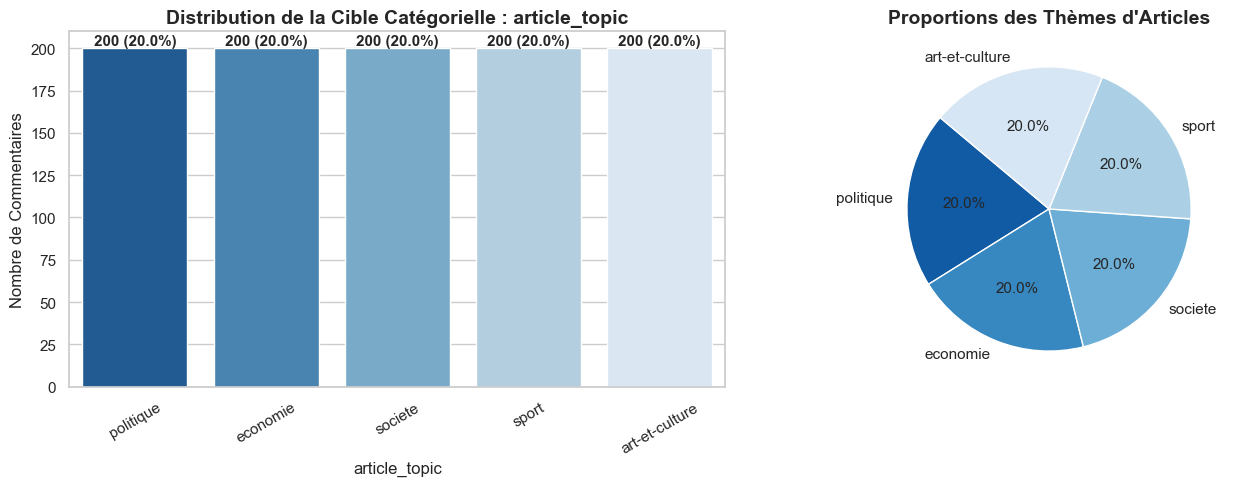

In [14]:
# Cible Catégorielle Principale : article_topic
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

topic_counts = df['article_topic'].value_counts()
sns.barplot(x=topic_counts.index, y=topic_counts.values, ax=ax[0], palette='Blues_r')
ax[0].set_title("Distribution de la Cible Catégorielle : article_topic", fontweight='bold')
ax[0].set_ylabel("Nombre de Commentaires")
ax[0].tick_params(axis='x', rotation=30)

for i, v in enumerate(topic_counts.values):
    ax[0].text(i, v + 2, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

ax[1].pie(topic_counts.values, labels=topic_counts.index, autopct='%1.1f%%',
          startangle=140, colors=sns.color_palette('Blues_r', len(topic_counts)))
ax[1].set_title("Proportions des Thèmes d'Articles", fontweight='bold')

plt.tight_layout()
plt.show()

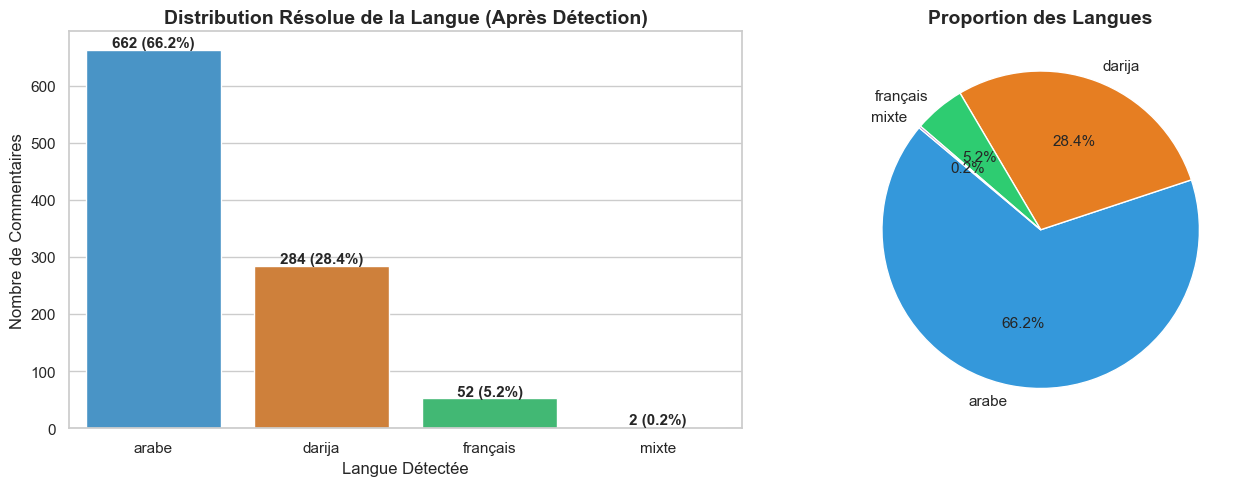

In [15]:
# Nouvelle Variable Résolue : Distribution Réelle de la Langue
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

lang_counts = df['language'].value_counts()
colors_lang = {'arabe': '#3498db', 'darija': '#e67e22', 'français': '#2ecc71', 'mixte': '#9b59b6'}

sns.barplot(x=lang_counts.index, y=lang_counts.values, ax=ax[0],
            palette=[colors_lang.get(l, '#95a5a6') for l in lang_counts.index])
ax[0].set_title("Distribution Résolue de la Langue (Après Détection)", fontweight='bold')
ax[0].set_ylabel("Nombre de Commentaires")
ax[0].set_xlabel("Langue Détectée")

for i, v in enumerate(lang_counts.values):
    ax[0].text(i, v + 5, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

ax[1].pie(lang_counts.values, labels=lang_counts.index, autopct='%1.1f%%',
          startangle=140, colors=[colors_lang.get(l, '#95a5a6') for l in lang_counts.index])
ax[1].set_title("Proportion des Langues", fontweight='bold')

plt.tight_layout()
plt.show()

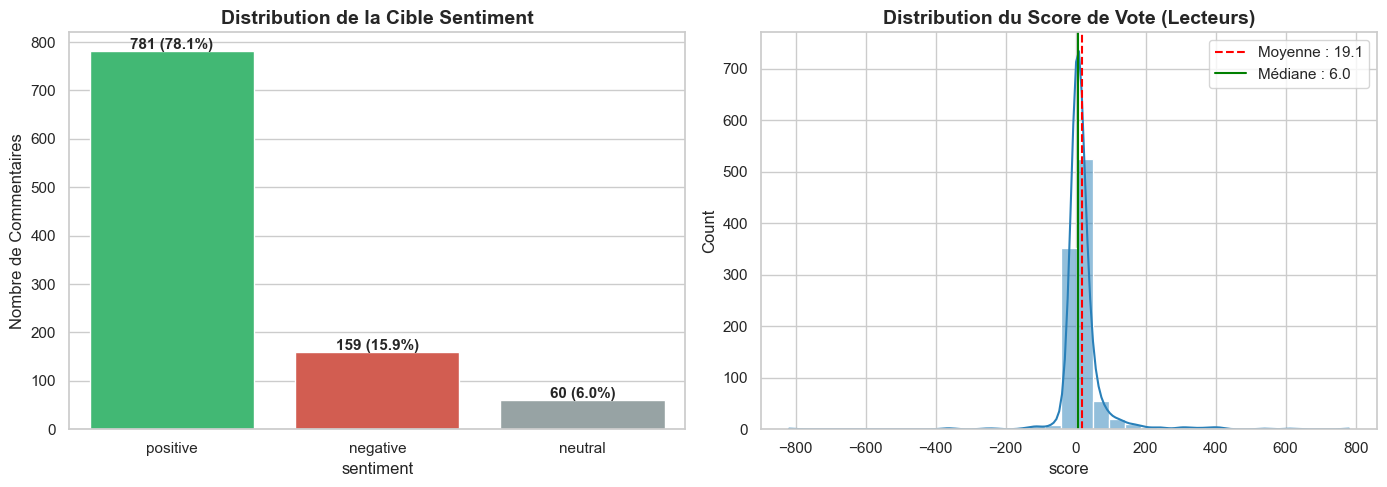

In [16]:
# Cible Sentiment & Distribution du Score Numérique
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Sentiment barplot
sentiment_counts = df['sentiment'].value_counts()
colors_sent = {'positive': '#2ecc71', 'negative': '#e74c3c', 'neutral': '#95a5a6'}
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values, ax=ax[0],
            palette=[colors_sent[s] for s in sentiment_counts.index])
ax[0].set_title("Distribution de la Cible Sentiment", fontweight='bold')
ax[0].set_ylabel("Nombre de Commentaires")

for i, v in enumerate(sentiment_counts.values):
    ax[0].text(i, v + 4, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Histogramme du Score avec KDE
sns.histplot(df['score'], kde=True, ax=ax[1], color='#2980b9', bins=35)
ax[1].set_title("Distribution du Score de Vote (Lecteurs)", fontweight='bold')
ax[1].axvline(df['score'].mean(), color='red', linestyle='--', label=f"Moyenne : {df['score'].mean():.1f}")
ax[1].axvline(df['score'].median(), color='green', linestyle='-', label=f"Médiane : {df['score'].median():.1f}")
ax[1].legend()

plt.tight_layout()
plt.show()

### 3.2 Analyse Bivariée

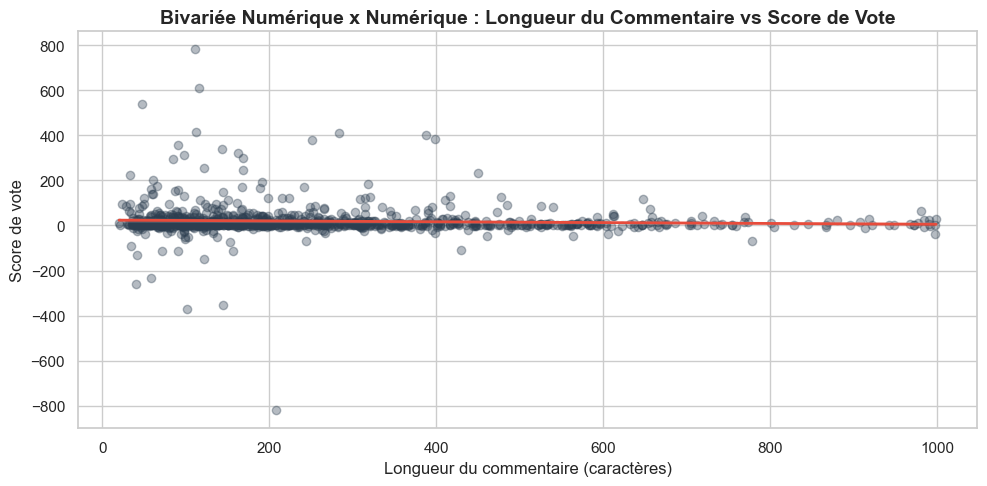

Coefficient de corrélation de Pearson (Longueur vs Score) : -0.055


In [17]:
# Préparation de variables numériques
df['char_length'] = df['comment_text_clean'].str.len()
df['word_count'] = df['comment_text_clean'].str.split().str.len()

# Numérique x Numérique : Longueur du commentaire (char_length) vs Score
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='char_length', y='score',
            scatter_kws={'alpha': 0.35, 'color': '#2c3e50'},
            line_kws={'color': '#e74c3c', 'linewidth': 2})
plt.title("Bivariée Numérique x Numérique : Longueur du Commentaire vs Score de Vote", fontweight='bold')
plt.xlabel("Longueur du commentaire (caractères)")
plt.ylabel("Score de vote")
plt.tight_layout()
plt.show()

corr_len_score = df['char_length'].corr(df['score'])
print(f"Coefficient de corrélation de Pearson (Longueur vs Score) : {corr_len_score:.3f}")

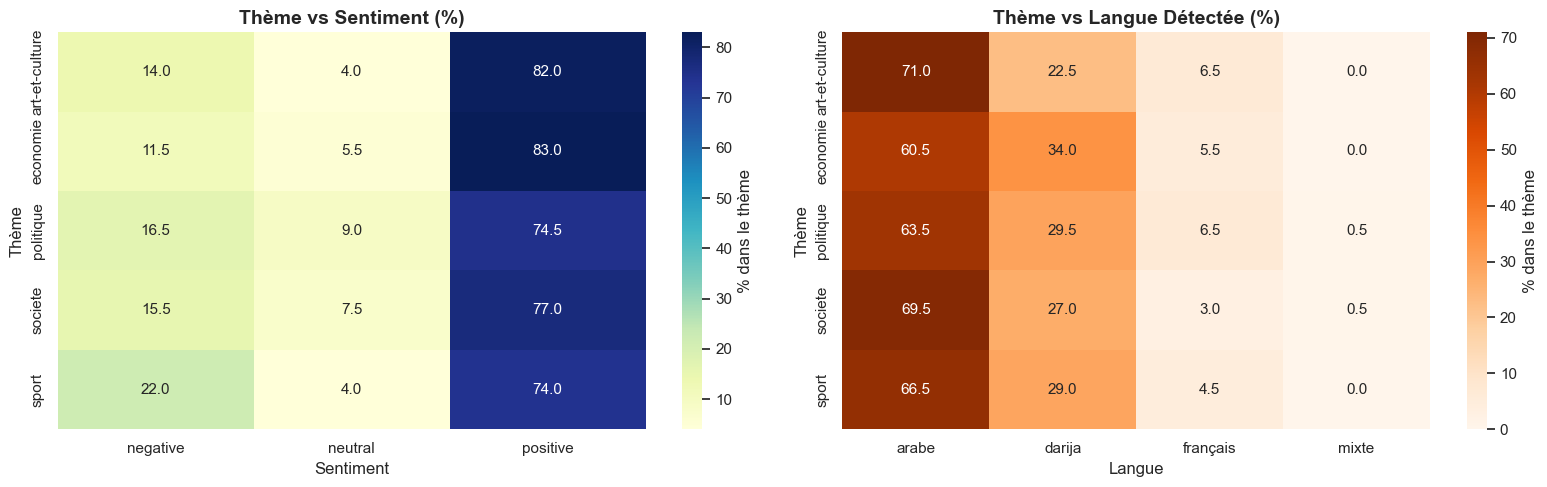

In [18]:
# Catégorielle x Catégorielle : A. Thème vs Sentiment | B. Thème vs Langue
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# A. Thème vs Sentiment
ct_sent = pd.crosstab(df['article_topic'], df['sentiment'], normalize='index') * 100
sns.heatmap(ct_sent, annot=True, fmt='.1f', cmap='YlGnBu', ax=ax[0], cbar_kws={'label': '% dans le thème'})
ax[0].set_title("Thème vs Sentiment (%)", fontweight='bold')
ax[0].set_ylabel("Thème")
ax[0].set_xlabel("Sentiment")

# B. Thème vs Langue
ct_lang = pd.crosstab(df['article_topic'], df['language'], normalize='index') * 100
sns.heatmap(ct_lang, annot=True, fmt='.1f', cmap='Oranges', ax=ax[1], cbar_kws={'label': '% dans le thème'})
ax[1].set_title("Thème vs Langue Détectée (%)", fontweight='bold')
ax[1].set_ylabel("Thème")
ax[1].set_xlabel("Langue")

plt.tight_layout()
plt.show()

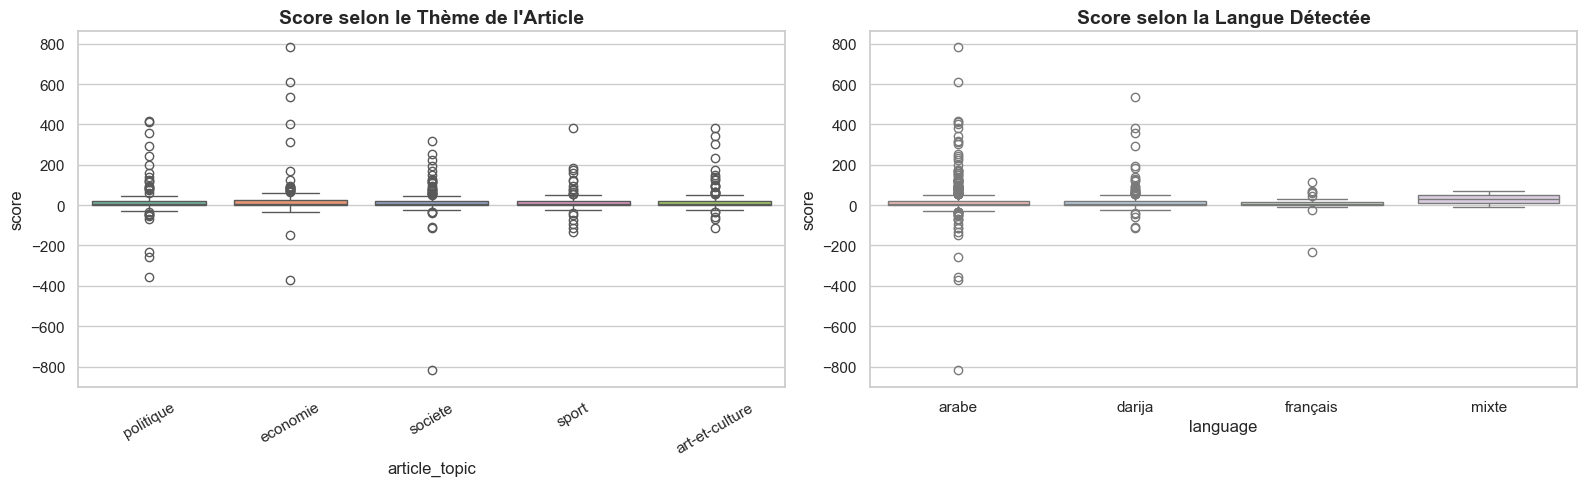

In [19]:
# Numérique x Catégorielle : Distribution du Score selon le Thème et la Langue
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Score selon le thème
sns.boxplot(data=df, x='article_topic', y='score', ax=ax[0], palette='Set2')
ax[0].set_title("Score selon le Thème de l'Article", fontweight='bold')
ax[0].tick_params(axis='x', rotation=30)

# Score selon la langue
sns.boxplot(data=df, x='language', y='score', ax=ax[1], palette='Pastel1')
ax[1].set_title("Score selon la Langue Détectée", fontweight='bold')

plt.tight_layout()
plt.show()

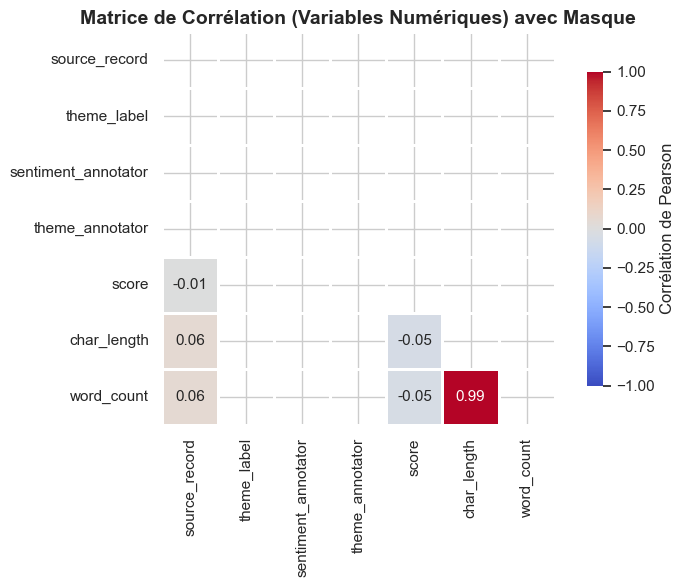

In [20]:
# Matrice de Corrélation avec MASQUE TRIANGULAIRE pour une lisibilité maximale
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

# Création du masque triangulaire supérieur (np.triu)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1,
    square=True,
    cbar_kws={"shrink": .8, "label": "Corrélation de Pearson"}
)
plt.title("Matrice de Corrélation (Variables Numériques) avec Masque", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.3 Analyse Multivariée

Croisement simultané du nombre de mots, du score, du thème d'article et de la langue détectée.

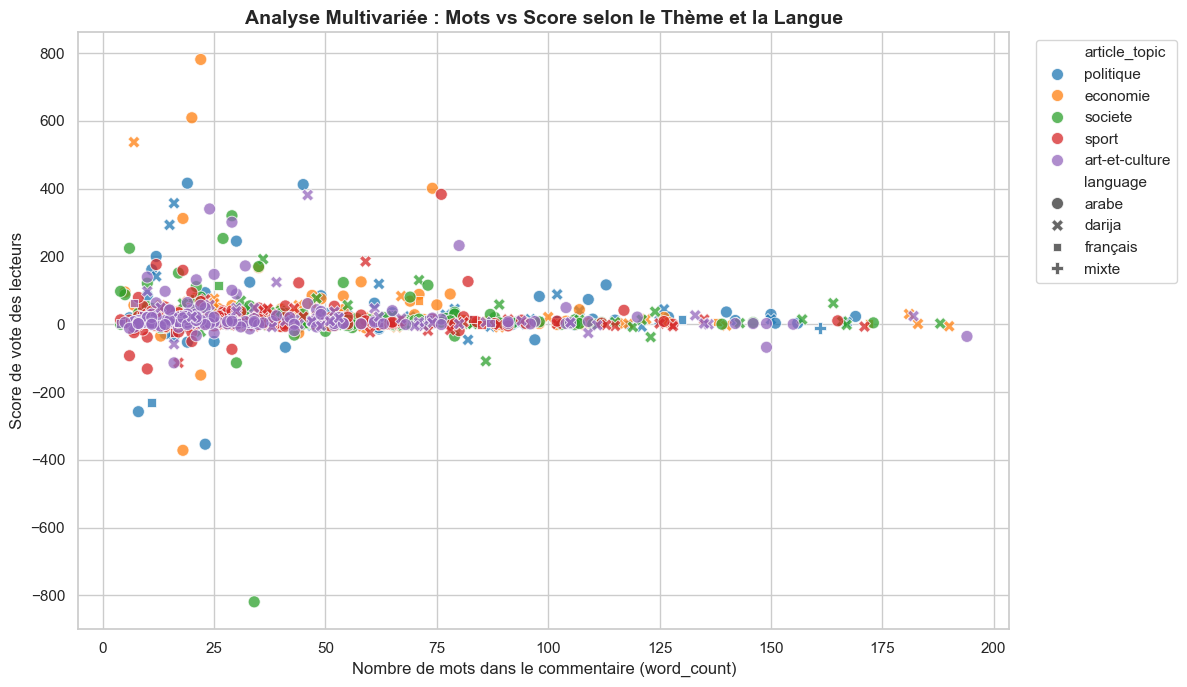

In [21]:
# Analyse Multivariée : Nuage de points 4D
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df,
    x='word_count',
    y='score',
    hue='article_topic',
    style='language',
    s=75,
    alpha=0.75,
    palette='tab10'
)
plt.title("Analyse Multivariée : Mots vs Score selon le Thème et la Langue", fontweight='bold')
plt.xlabel("Nombre de mots dans le commentaire (word_count)")
plt.ylabel("Score de vote des lecteurs")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 4. Feature Engineering

Nous construisons des caractéristiques pour les futurs modèles de Machine Learning :
1. **Métriques de texte brutes :** `char_length`, `word_count`, `avg_word_length`, `unique_word_count`.
2. **Richesse lexicale :** `lexical_diversity` (Type-Token Ratio, TTR).
3. **Ponctuation & Expressivité :** `punctuation_count`, `exclamation_count`, `question_count`.
4. **Typologie linguistique :**
   - `arabic_char_count` et `arabic_ratio` (proportion d'alphabet arabe)
   - `has_latin_script` (présence de Darija Arabizi ou français)
   - `digit_count` (chiffres présents)
5. **Cibles encodées pour le ML :**
   - `target_sentiment` (`-1` = négatif, `0` = neutre, `1` = positif)
   - `target_topic` (`0` à `4` pour les rubriques)
   - `target_language` (`0` à `3` pour la langue détectée)

In [22]:
def extract_features(data):
    df_feat = data.copy()

    # 1. Métriques de base
    df_feat['char_length'] = df_feat['comment_text_clean'].str.len()
    df_feat['word_count'] = df_feat['comment_text_clean'].str.split().str.len().replace(0, 1)
    df_feat['avg_word_length'] = (df_feat['char_length'] / df_feat['word_count']).round(2)
    df_feat['unique_word_count'] = df_feat['comment_text_clean'].apply(lambda x: len(set(x.split())))
    df_feat['lexical_diversity'] = (df_feat['unique_word_count'] / df_feat['word_count']).round(3)

    # 2. Ponctuation et marqueurs d'expressivité
    df_feat['punctuation_count'] = df_feat['comment_text_clean'].apply(lambda x: len(re.findall(r'[^\w\s]', x)))
    df_feat['exclamation_count'] = df_feat['comment_text_clean'].apply(lambda x: x.count('!'))
    df_feat['question_count'] = df_feat['comment_text_clean'].apply(lambda x: x.count('?') + x.count('\u061f'))
    df_feat['digit_count'] = df_feat['comment_text_clean'].apply(lambda x: len(re.findall(r'\d', x)))

    # 3. Détection linguistique et typologique
    arabic_pattern = re.compile(r'[\u0600-\u06FF\u0750-\u077F]')
    latin_pattern = re.compile(r'[a-zA-Z]')

    df_feat['arabic_char_count'] = df_feat['comment_text_clean'].apply(lambda x: len(arabic_pattern.findall(x)))
    df_feat['arabic_ratio'] = (df_feat['arabic_char_count'] / df_feat['char_length'].replace(0, 1)).round(3)
    df_feat['has_latin_script'] = df_feat['comment_text_clean'].apply(lambda x: int(bool(latin_pattern.search(x))))

    # 4. Encodage des cibles pour le Machine Learning
    sentiment_map = {'negative': -1, 'neutral': 0, 'positive': 1}
    df_feat['target_sentiment'] = df_feat['sentiment'].map(sentiment_map)

    topics = sorted(df_feat['article_topic'].unique())
    topic_map = {topic: idx for idx, topic in enumerate(topics)}
    df_feat['target_topic'] = df_feat['article_topic'].map(topic_map)

    lang_map = {'arabe': 0, 'darija': 1, 'français': 2, 'mixte': 3}
    df_feat['target_language'] = df_feat['language'].map(lang_map).fillna(0).astype(int)

    return df_feat

df_engineered = extract_features(df)
print("Feature Engineering effectue avec succes. Nombre total de colonnes :", df_engineered.shape[1])

Feature Engineering effectue avec succes. Nombre total de colonnes : 32


In [23]:
# Aperçu des variables créées
feature_cols = [
    'char_length', 'word_count', 'avg_word_length', 'lexical_diversity',
    'punctuation_count', 'exclamation_count', 'question_count',
    'arabic_ratio', 'has_latin_script', 'target_sentiment', 'target_topic', 'target_language'
]
df_engineered[feature_cols].head(8)

,char_length,word_count,avg_word_length,lexical_diversity,punctuation_count,exclamation_count,question_count,arabic_ratio,has_latin_script,target_sentiment,target_topic,target_language
0,244,41,5.95,0.878,4,0,0,0.836,0,-1,2,0
1,70,12,5.83,1.000,0,0,0,0.843,0,1,2,0
2,56,13,4.31,0.923,1,0,0,0.768,0,1,2,0
3,91,15,6.07,0.933,1,0,0,0.835,0,1,2,0
4,122,21,5.81,0.905,1,0,0,0.836,0,-1,2,0
5,289,52,5.56,0.923,5,0,0,0.806,0,1,2,0
6,30,5,6.00,1.000,2,0,0,0.800,0,1,2,1
7,718,126,5.70,0.810,8,0,0,0.815,0,1,2,1


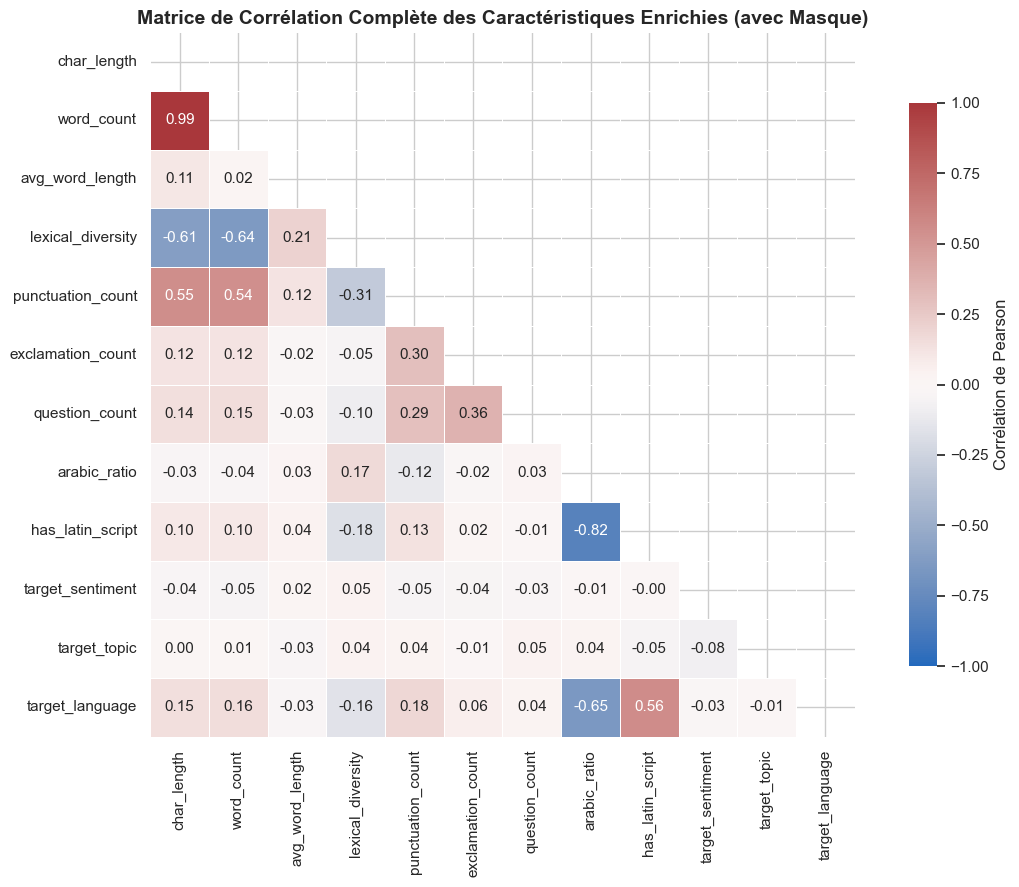

In [24]:
# Matrice de Corrélation Finale des Nouvelles Caractéristiques avec Masque
plt.figure(figsize=(12, 9))
corr_eng = df_engineered[feature_cols].corr()
mask_final = np.triu(np.ones_like(corr_eng, dtype=bool))

sns.heatmap(
    corr_eng,
    mask=mask_final,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8, "label": "Corrélation de Pearson"}
)
plt.title("Matrice de Corrélation Complète des Caractéristiques Enrichies (avec Masque)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Synthèse & Sauvegarde pour la Modélisation ML

Toutes les données nettoyées, avec la **langue résolue** et les nouvelles caractéristiques pour le Machine Learning, sont exportées :
- `data/processed/hespress/comments_features_engineered.csv`
- `data/processed/hespress/comments_features_engineered.parquet`

In [25]:
# Sauvegarde des données finales enrichies
output_csv = PROJECT_ROOT / "data" / "processed" / "hespress" / "comments_features_engineered.csv"
output_parquet = PROJECT_ROOT / "data" / "processed" / "hespress" / "comments_features_engineered.parquet"

df_engineered.to_csv(output_csv, index=False, encoding='utf-8-sig')
try:
    df_engineered.to_parquet(output_parquet, index=False)
    print(f"Données sauvegardées en Parquet : {output_parquet}")
except Exception as e:
    print(f"Sauvegarde Parquet ignorée : {e}")

print(f"Données sauvegardées en CSV : {output_csv}")
print(f"Total lignes : {len(df_engineered)}, Total colonnes : {df_engineered.shape[1]}")

Données sauvegardées en Parquet : ..\data\processed\hespress\comments_features_engineered.parquet
Données sauvegardées en CSV : ..\data\processed\hespress\comments_features_engineered.csv
Total lignes : 1000, Total colonnes : 32
